# Partie 5 — Évaluation & interprétation

Responsable : Membre 5 ([@harounambaye](https://github.com/harounambaye))

**Objectif** : évaluer honnêtement les trois modèles optimisés de la partie 4 sur le jeu de test, choisir le seuil de décision à partir d'un coût métier, interpréter le modèle final et conclure.

**Règles suivies**
- Le jeu de test est utilisé **une seule fois** pour mesurer les modèles. Aucun réglage n'est modifié après l'avoir vu.
- Le modèle final (régression logistique) a été **désigné avant** de regarder le test, sur des critères de validation croisée et de simplicité (voir `docs/partie-4-entrainement-optimisation.md`, section 10). Le test sert à confirmer ce choix, pas à le faire.
- Le **seuil de décision** est choisi sur des prédictions *out-of-fold* du train, jamais sur le test.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import joblib
import sklearn
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, roc_curve, precision_recall_curve,
                             ConfusionMatrixDisplay, brier_score_loss)
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve

warnings.filterwarnings("ignore", category=UserWarning)
SEED = 42
OUT_DIR = Path("outputs"); MODELS_DIR = Path("../models"); REPORTS_DIR = Path("../reports"); FIG_DIR = REPORTS_DIR / "figures"
sns.set_theme(style="whitegrid", context="notebook")
print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | scikit-learn {sklearn.__version__}")

Python 3.13.2 | pandas 3.1.1 | scikit-learn 1.9.1


## 1. Données et modèles

In [2]:
df = pd.read_csv(OUT_DIR / "telco_clean_features.csv")
X = df.drop(columns=["Churn", "customerID"]); y = df["Churn"]; ids = df["customerID"]
X_train, X_test, y_train, y_test, id_train, id_test = train_test_split(
    X, y, ids, test_size=0.20, stratify=y, random_state=SEED)

# Le test doit etre exactement celui des parties 3 et 4
ref_test = pd.read_csv(OUT_DIR / "test_processed.csv", usecols=["customerID"])
assert set(id_test) == set(ref_test["customerID"]), "Le test n'est pas celui de la partie 3"
print(f"Train : {X_train.shape} ({y_train.mean():.2%} churn) | Test : {X_test.shape} ({y_test.mean():.2%} churn)")

MODELES = {"Régression logistique": joblib.load(MODELS_DIR / "logreg_optimisee.joblib"),
           "Forêt aléatoire": joblib.load(MODELS_DIR / "foret_optimisee.joblib"),
           "Arbre de décision": joblib.load(MODELS_DIR / "arbre_optimise.joblib")}
for nom, m in MODELES.items():
    print(f"{nom:24s} -> {type(m.steps[-1][1]).__name__}")

Train : (5634, 43) (26.54% churn) | Test : (1409, 43) (26.54% churn)


Régression logistique    -> LogisticRegression
Forêt aléatoire          -> RandomForestClassifier
Arbre de décision        -> DecisionTreeClassifier


## 2. Évaluation sur le jeu de test (seuil 0,5)

Une seule passe : on calcule les probabilités de churn sur le test, puis les métriques au seuil par défaut de 0,5. On compare ensuite aux scores de validation croisée de la partie 4. Un écart important signalerait un problème (sur-apprentissage de la sélection, fuite de données…).

In [3]:
def metriques(y_true, proba, seuil=0.5):
    pred = (proba >= seuil).astype(int)
    return {"accuracy": accuracy_score(y_true, pred), "precision": precision_score(y_true, pred),
            "recall": recall_score(y_true, pred), "f1": f1_score(y_true, pred),
            "roc_auc": roc_auc_score(y_true, proba), "pr_auc": average_precision_score(y_true, proba)}

proba_test = {nom: m.predict_proba(X_test)[:, 1] for nom, m in MODELES.items()}   # UNE seule fois
res_test = pd.DataFrame({nom: metriques(y_test, p) for nom, p in proba_test.items()}).T

# Scores de validation croisee de la partie 4
cv = pd.read_csv(REPORTS_DIR / "tableau_comparatif_experiences.csv").set_index("experience")
cv_map = {"Régression logistique": "Régression logistique optimisée", "Forêt aléatoire": "Forêt aléatoire optimisée",
          "Arbre de décision": "Arbre de décision optimisé"}
comp = pd.DataFrame({
    "F1 validation (CV)": [cv.loc[v, "f1_moy"] for v in cv_map.values()],
    "F1 test": res_test["f1"].values,
    "ROC-AUC validation (CV)": [cv.loc[v, "roc_auc_moy"] for v in cv_map.values()],
    "ROC-AUC test": res_test["roc_auc"].values}, index=list(cv_map))
comp["écart F1"] = comp["F1 test"] - comp["F1 validation (CV)"]
comp["écart ROC-AUC"] = comp["ROC-AUC test"] - comp["ROC-AUC validation (CV)"]
print("Test, seuil 0,5 :"); display(res_test.round(3))
print("Validation croisée vs test :"); display(comp.round(3))

Test, seuil 0,5 :


,accuracy,precision,recall,f1,roc_auc,pr_auc
Régression logistique,0.750,0.519,0.799,0.629,0.846,0.659
Forêt aléatoire,0.752,0.522,0.781,0.626,0.842,0.658
Arbre de décision,0.745,0.513,0.807,0.627,0.829,0.632


Validation croisée vs test :


,F1 validation (CV),F1 test,ROC-AUC validation (CV),ROC-AUC test,écart F1,écart ROC-AUC
Régression logistique,0.635,0.629,0.849,0.846,-0.005,-0.002
Forêt aléatoire,0.634,0.626,0.846,0.842,-0.008,-0.004
Arbre de décision,0.621,0.627,0.832,0.829,0.006,-0.004


**Lecture.** Les écarts entre validation croisée et test sont à comparer à l'écart-type entre plis de la partie 4 (≈ 0,013 à 0,021 sur le F1). Un écart du même ordre est normal ; il n'y a pas de signe de fuite de données si les scores de test ne sont pas nettement meilleurs que ceux de validation.

### Incertitude sur le test : intervalle de confiance par bootstrap

In [4]:
rng = np.random.default_rng(SEED)
y_arr = y_test.to_numpy(); n = len(y_arr)
idx_boot = [rng.integers(0, n, n) for _ in range(1000)]
def boot_ci(nom, fn):
    p = proba_test[nom]
    vals = [fn(y_arr[i], p[i]) for i in idx_boot]
    return np.percentile(vals, [2.5, 97.5])
lignes = []
for nom in MODELES:
    f1_lo, f1_hi = boot_ci(nom, lambda yt, p: f1_score(yt, (p >= .5).astype(int)))
    au_lo, au_hi = boot_ci(nom, roc_auc_score)
    lignes.append({"modèle": nom, "F1": res_test.loc[nom, "f1"], "F1 IC95%": f"[{f1_lo:.3f} ; {f1_hi:.3f}]",
                   "ROC-AUC": res_test.loc[nom, "roc_auc"], "ROC-AUC IC95%": f"[{au_lo:.3f} ; {au_hi:.3f}]"})
ic = pd.DataFrame(lignes).set_index("modèle"); display(ic.round(3))

,F1,F1 IC95%,ROC-AUC,ROC-AUC IC95%
modèle,,,,
Régression logistique,0.629,[0.592 ; 0.663],0.846,[0.824 ; 0.867]
Forêt aléatoire,0.626,[0.588 ; 0.660],0.842,[0.819 ; 0.863]
Arbre de décision,0.627,[0.590 ; 0.662],0.829,[0.804 ; 0.852]


Les intervalles se chevauchent largement : avec 1 409 clients de test (≈ 374 churners), les différences entre les trois modèles ne sont pas significatives. Ce constat confirme la partie 4 et justifie de choisir sur la simplicité.

## 3. Matrices de confusion, ROC et précision-rappel

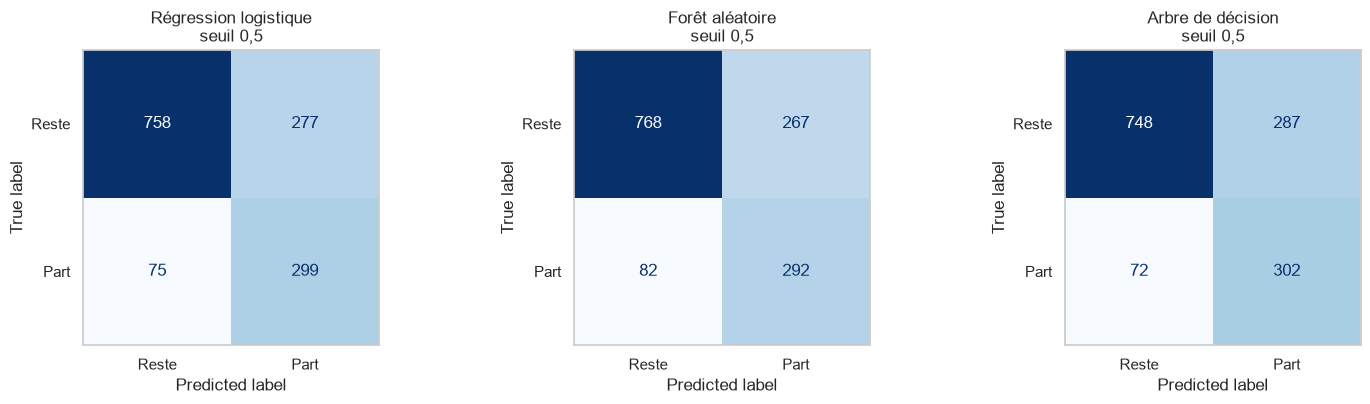

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (nom, p) in zip(axes, proba_test.items()):
    cm = confusion_matrix(y_test, (p >= .5).astype(int))
    ConfusionMatrixDisplay(cm, display_labels=["Reste", "Part"]).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(f"{nom}\nseuil 0,5"); ax.grid(False)
plt.tight_layout(); plt.savefig(FIG_DIR / "eval_matrices_confusion.png", dpi=150, bbox_inches="tight"); plt.show()

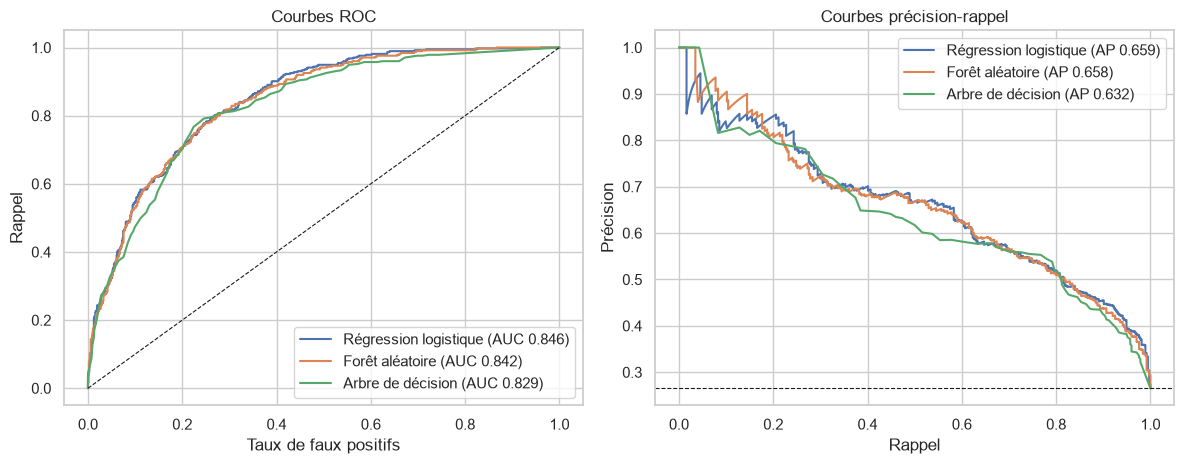

In [6]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.8))
for nom, p in proba_test.items():
    fpr, tpr, _ = roc_curve(y_test, p); a1.plot(fpr, tpr, label=f"{nom} (AUC {roc_auc_score(y_test, p):.3f})")
    pr, rc, _ = precision_recall_curve(y_test, p); a2.plot(rc, pr, label=f"{nom} (AP {average_precision_score(y_test, p):.3f})")
a1.plot([0, 1], [0, 1], "k--", lw=.8); a1.set(xlabel="Taux de faux positifs", ylabel="Rappel", title="Courbes ROC"); a1.legend(loc="lower right")
a2.axhline(y_test.mean(), color="k", ls="--", lw=.8); a2.set(xlabel="Rappel", ylabel="Précision", title="Courbes précision-rappel"); a2.legend(loc="upper right")
plt.tight_layout(); plt.savefig(FIG_DIR / "eval_roc_pr.png", dpi=150, bbox_inches="tight"); plt.show()

## 4. Choix du seuil de décision à partir d'un coût métier

Le seuil 0,5 n'a aucune raison d'être optimal. On le choisit en minimisant un **coût** :

- un **faux négatif** (client qui part, non détecté) coûte `C_FN` : le revenu perdu ;
- un **faux positif** (client fidèle contacté pour rien) coûte `C_FP` : le coût de l'action de fidélisation (remise, appel).

Seul le **rapport** `C_FN / C_FP` compte. Les vrais coûts ne sont pas dans le jeu de données : on fait donc une **hypothèse explicite** (rapport de 5, soit une remise ou un appel qui coûte environ cinq fois moins que la perte d'un client) et on teste la sensibilité du résultat à cette hypothèse.

**Méthode rigoureuse** : le seuil est choisi sur des prédictions *out-of-fold* du train (validation croisée à 5 plis), puis appliqué une seule fois au test.

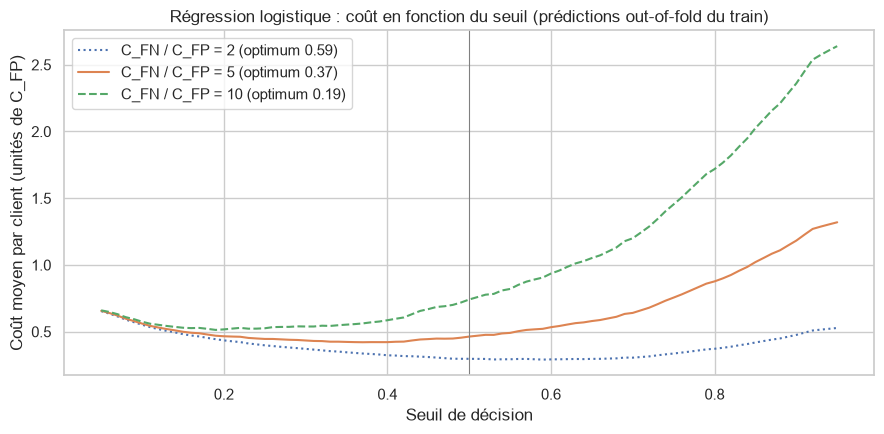

In [7]:
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
proba_oof = {nom: cross_val_predict(m, X_train, y_train, cv=cv5, method="predict_proba")[:, 1]
             for nom, m in MODELES.items()}

def cout_moyen(y_true, proba, seuil, ratio):
    pred = proba >= seuil
    fn = ((~pred) & (y_true == 1)).sum(); fp = (pred & (y_true == 0)).sum()
    return (ratio * fn + fp) / len(y_true)          # en unites de C_FP par client

seuils = np.linspace(0.05, 0.95, 91)
def meilleur_seuil(nom, ratio):
    c = [cout_moyen(y_train.to_numpy(), proba_oof[nom], s, ratio) for s in seuils]
    return seuils[int(np.argmin(c))]

RATIO = 5
fig, ax = plt.subplots(figsize=(9, 4.5))
for r, ls in [(2, ":"), (5, "-"), (10, "--")]:
    c = [cout_moyen(y_train.to_numpy(), proba_oof["Régression logistique"], s, r) for s in seuils]
    ax.plot(seuils, c, ls, label=f"C_FN / C_FP = {r} (optimum {seuils[int(np.argmin(c))]:.2f})")
ax.axvline(.5, color="grey", lw=.8); ax.set(xlabel="Seuil de décision", ylabel="Coût moyen par client (unités de C_FP)",
    title="Régression logistique : coût en fonction du seuil (prédictions out-of-fold du train)"); ax.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "eval_cout_seuil.png", dpi=150, bbox_inches="tight"); plt.show()

In [8]:
# Sensibilite du seuil optimal au rapport de couts
sens = pd.DataFrame({r: {nom: meilleur_seuil(nom, r) for nom in MODELES} for r in [1, 2, 3, 5, 8, 10, 15]})
sens.columns = [f"ratio {r}" for r in sens.columns]; print("Seuil optimal (train, out-of-fold) selon le rapport C_FN/C_FP :"); display(sens.round(2))

Seuil optimal (train, out-of-fold) selon le rapport C_FN/C_FP :


,ratio 1,ratio 2,ratio 3,ratio 5,ratio 8,ratio 10,ratio 15
Régression logistique,0.72,0.59,0.48,0.37,0.24,0.19,0.19
Forêt aléatoire,0.67,0.59,0.52,0.35,0.29,0.18,0.15
Arbre de décision,0.80,0.50,0.50,0.34,0.20,0.17,0.11


In [9]:
SEUILS_FINAUX = {nom: meilleur_seuil(nom, RATIO) for nom in MODELES}
lignes = []
for nom, p in proba_test.items():
    for etiquette, s in [("seuil 0,5", 0.5), (f"seuil coût ({SEUILS_FINAUX[nom]:.2f})", SEUILS_FINAUX[nom])]:
        pred = (p >= s).astype(int); tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
        lignes.append({"modèle": nom, "règle": etiquette, "precision": precision_score(y_test, pred),
                       "recall": recall_score(y_test, pred), "f1": f1_score(y_test, pred),
                       "FN": fn, "FP": fp, "coût moyen": cout_moyen(y_test.to_numpy(), p, s, RATIO)})
tab_seuil = pd.DataFrame(lignes).set_index(["modèle", "règle"]); display(tab_seuil.round(3))

precision  recall     f1  FN   FP  \
modèle                règle                                                  
Régression logistique seuil 0,5              0.519   0.799  0.629  75  277   
                      seuil coût (0.37)      0.457   0.888  0.604  42  394   
Forêt aléatoire       seuil 0,5              0.522   0.781  0.626  82  267   
                      seuil coût (0.35)      0.449   0.885  0.595  43  407   
Arbre de décision     seuil 0,5              0.513   0.807  0.627  72  287   
                      seuil coût (0.34)      0.426   0.898  0.578  38  452   

                                         coût moyen  
modèle                règle                          
Régression logistique seuil 0,5               0.463  
                      seuil coût (0.37)       0.429  
Forêt aléatoire       seuil 0,5               0.480  
                      seuil coût (0.35)       0.441  
Arbre de décision     seuil 0,5               0.459  
                      seuil coût (0.34)       0.456

**Lecture.** Quand rater un churner coûte plus cher qu'un contact inutile, le seuil optimal descend sous 0,5 : on accepte plus de faux positifs pour détecter plus de clients à risque. Le coût moyen baisse par rapport à 0,5 sur le test, ce qui confirme que le seuil choisi sur le train se généralise. Le seuil final **dépend directement du rapport de coûts réel**, que l'entreprise doit fournir : le tableau de sensibilité montre comment l'ajuster.

## 5. Choix du modèle final

Les trois modèles sont statistiquement au même niveau (intervalles de confiance qui se chevauchent). On retient la **régression logistique** :

| Critère | Régression logistique | Forêt aléatoire | Arbre |
|---|---|---|---|
| Performance (F1 / ROC-AUC) | équivalente | équivalente | un peu en dessous (ROC-AUC) |
| Interprétabilité | coefficients lisibles | importances globales seulement | règles lisibles mais instables |
| Taille du fichier | 4 Ko | 400 Ko | 10 Ko |
| Rapidité de prédiction | très rapide | plus lente | rapide |
| Probabilités calibrées | à vérifier ci-dessous | à vérifier | peu fiables |

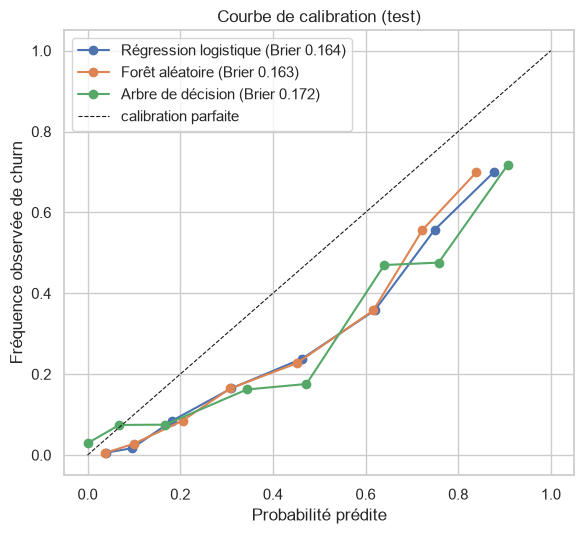

In [10]:
fig, ax = plt.subplots(figsize=(6, 5.5))
for nom, p in proba_test.items():
    frac, moy = calibration_curve(y_test, p, n_bins=8, strategy="quantile")
    ax.plot(moy, frac, "o-", label=f"{nom} (Brier {brier_score_loss(y_test, p):.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=.8, label="calibration parfaite")
ax.set(xlabel="Probabilité prédite", ylabel="Fréquence observée de churn", title="Courbe de calibration (test)"); ax.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "eval_calibration.png", dpi=150, bbox_inches="tight"); plt.show()

Les modèles ont été entraînés avec `class_weight="balanced"`: leurs probabilités sont **gonflées** pour la classe churn (elles sont au-dessus de la fréquence observée). Elles servent bien à **classer** les clients et à fixer un seuil, mais ne sont pas des probabilités réelles. Pour annoncer « ce client a 60 % de risque de partir », il faudrait recalibrer (par exemple `CalibratedClassifierCV`) : piste d'amélioration.

## 6. Analyse des erreurs (régression logistique, seuil coût)

In [11]:
MODELE = "Régression logistique"; S = SEUILS_FINAUX[MODELE]
ev = X_test.copy(); ev["Churn"] = y_test.values; ev["proba"] = proba_test[MODELE]
ev["pred"] = (ev["proba"] >= S).astype(int)
ev["cas"] = np.select([(ev.Churn == 1) & (ev.pred == 1), (ev.Churn == 1) & (ev.pred == 0),
                       (ev.Churn == 0) & (ev.pred == 1)], ["VP (détecté)", "FN (raté)", "FP (fausse alerte)"], "VN")
print(ev["cas"].value_counts().to_string())
profil = ev.groupby("cas").agg(n=("Churn", "size"), tenure_moy=("tenure", "mean"), mensualite_moy=("MonthlyCharges", "mean"),
                               pct_mensuel=("Contract", lambda s: (s == "Month-to-month").mean()),
                               pct_fibre=("InternetService", lambda s: (s == "Fiber optic").mean()),
                               pct_cheque_elec=("PaymentMethod", lambda s: (s == "Electronic check").mean()))
display(profil.round(2))

cas
VN                    641
FP (fausse alerte)    394
VP (détecté)          332
FN (raté)              42


,n,tenure_moy,mensualite_moy,pct_mensuel,pct_fibre,pct_cheque_elec
cas,,,,,,
FN (raté),42,37.81,65.32,0.36,0.33,0.21
FP (fausse alerte),394,21.42,71.26,0.88,0.59,0.47
VN,641,47.38,54.62,0.15,0.20,0.13
VP (détecté),332,13.76,73.71,0.95,0.72,0.59


In [12]:
fn = ev[ev.cas == "FN (raté)"]; vp = ev[ev.cas == "VP (détecté)"]
print("Churners RATÉS (FN) vs DÉTECTÉS (VP) — part de chaque modalité :")
for col in ["Contract", "InternetService", "PaymentMethod", "tenure_group"]:
    t = pd.concat([fn[col].value_counts(normalize=True).rename("FN"), vp[col].value_counts(normalize=True).rename("VP")], axis=1).fillna(0)
    display(t.round(2))

Churners RATÉS (FN) vs DÉTECTÉS (VP) — part de chaque modalité :


,FN,VP
Contract,,
One year,0.43,0.05
Month-to-month,0.36,0.95
Two year,0.21,0.00


,FN,VP
InternetService,,
DSL,0.43,0.24
Fiber optic,0.33,0.72
No,0.24,0.05


,FN,VP
PaymentMethod,,
Bank transfer (automatic),0.33,0.13
Credit card (automatic),0.26,0.12
Electronic check,0.21,0.59
Mailed check,0.19,0.16


,FN,VP
tenure_group,,
25-48m,0.36,0.15
49-72m,0.33,0.06
7-12m,0.17,0.11
0-6m,0.10,0.51
13-24m,0.05,0.17


Les churners ratés ressemblent à des clients « stables » (contrat long, ancienneté élevée) : ils partent pour des raisons que les variables disponibles ne capturent pas (concurrence, déménagement, insatisfaction). C'est une **limite des données**, pas seulement du modèle.

## 7. Interprétation : quels facteurs poussent au départ ?

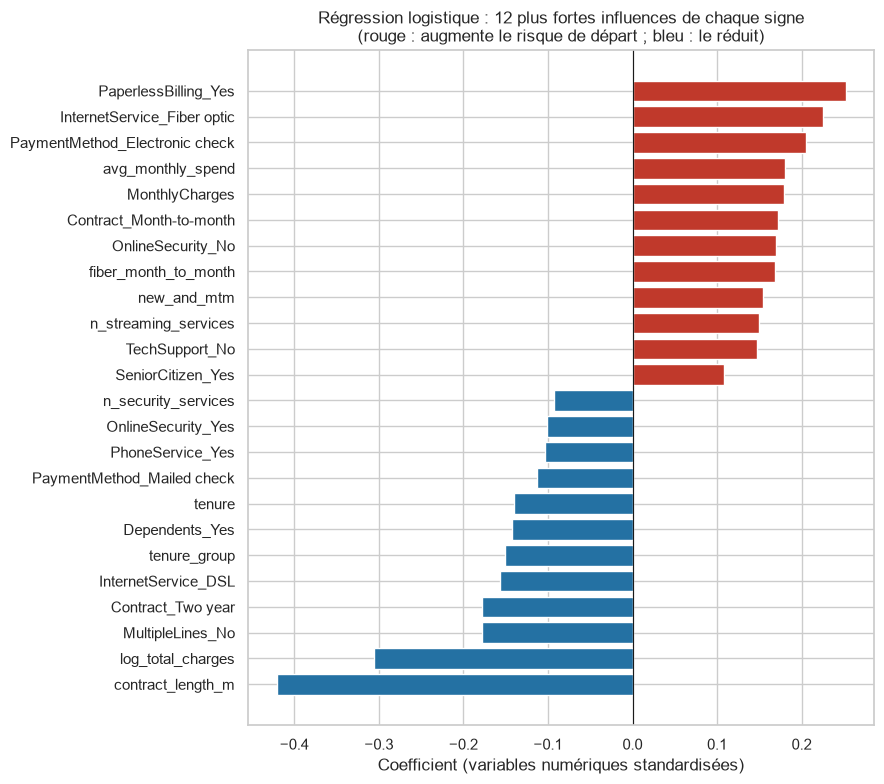

In [13]:
lr = MODELES[MODELE]; prep, clf = lr.named_steps["prep"], lr.named_steps["modele"]
coefs = pd.Series(clf.coef_[0], index=prep.get_feature_names_out()).sort_values()
top = pd.concat([coefs.head(12), coefs.tail(12)])
fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(top.index, top.values, color=np.where(top.values > 0, "#c0392b", "#2471a3"))
ax.axvline(0, color="k", lw=.8)
ax.set(title="Régression logistique : 12 plus fortes influences de chaque signe\n(rouge : augmente le risque de départ ; bleu : le réduit)",
       xlabel="Coefficient (variables numériques standardisées)")
plt.tight_layout(); plt.savefig(FIG_DIR / "eval_coefficients_logreg.png", dpi=150, bbox_inches="tight"); plt.show()

In [14]:
print("Variables qui augmentent le plus le risque :"); display(coefs.tail(8)[::-1].round(3).to_frame("coef"))
print("Variables qui le réduisent le plus :"); display(coefs.head(8).round(3).to_frame("coef"))

Variables qui augmentent le plus le risque :


,coef
PaperlessBilling_Yes,0.252
InternetService_Fiber optic,0.226
PaymentMethod_Electronic check,0.205
avg_monthly_spend,0.180
MonthlyCharges,0.179
Contract_Month-to-month,0.172
OnlineSecurity_No,0.170
fiber_month_to_month,0.169


Variables qui le réduisent le plus :


,coef
contract_length_m,-0.421
log_total_charges,-0.306
MultipleLines_No,-0.178
Contract_Two year,-0.178
InternetService_DSL,-0.157
tenure_group,-0.151
Dependents_Yes,-0.142
tenure,-0.140


**Attention aux coefficients.** Plusieurs variables sont fortement corrélées (`tenure`, `TotalCharges`, `log_total_charges`, `avg_monthly_spend`, `MonthlyCharges`…) : la régularisation (`C = 0,01`) répartit l'effet entre elles et un coefficient isolé peut être trompeur. On croise donc avec l'importance par permutation, plus robuste, qui mesure la perte de ROC-AUC quand une variable d'origine est mélangée.

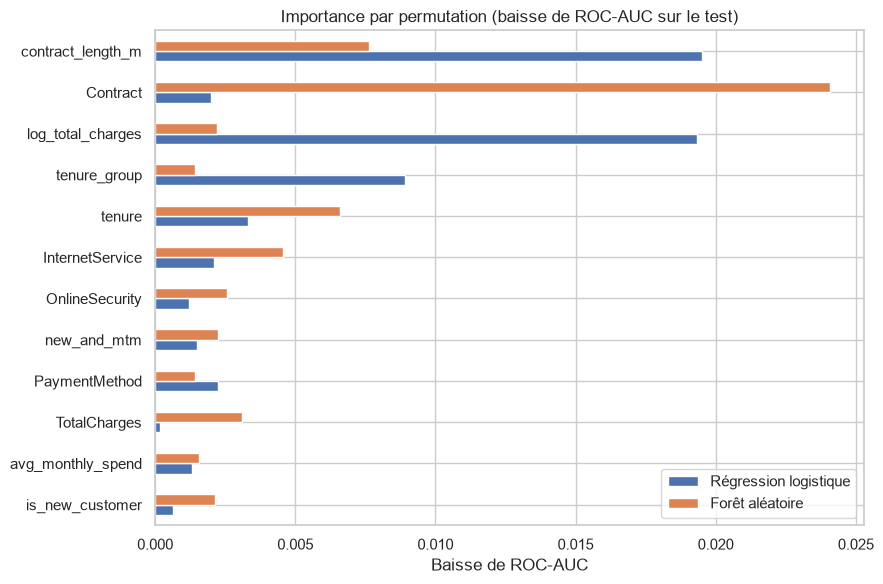

,Régression logistique,Forêt aléatoire,moyenne
contract_length_m,0.0195,0.0076,0.0136
Contract,0.0020,0.0241,0.0130
log_total_charges,0.0193,0.0022,0.0108
tenure_group,0.0089,0.0014,0.0052
tenure,0.0033,0.0066,0.0049
InternetService,0.0021,0.0046,0.0033
OnlineSecurity,0.0012,0.0026,0.0019
new_and_mtm,0.0015,0.0022,0.0019
PaymentMethod,0.0022,0.0014,0.0018
TotalCharges,0.0002,0.0031,0.0016


In [15]:
perm = {}
for nom in ["Régression logistique", "Forêt aléatoire"]:
    r = permutation_importance(MODELES[nom], X_test, y_test, scoring="roc_auc", n_repeats=15, random_state=SEED, n_jobs=1)
    perm[nom] = pd.Series(r.importances_mean, index=X_test.columns)
perm = pd.DataFrame(perm); perm["moyenne"] = perm.mean(axis=1)
top_perm = perm.sort_values("moyenne", ascending=False).head(12)
ax = top_perm[["Régression logistique", "Forêt aléatoire"]].iloc[::-1].plot.barh(figsize=(9, 6))
ax.set(title="Importance par permutation (baisse de ROC-AUC sur le test)", xlabel="Baisse de ROC-AUC")
plt.tight_layout(); plt.savefig(FIG_DIR / "eval_importance_permutation.png", dpi=150, bbox_inches="tight"); plt.show()
display(top_perm.round(4))

### Les modèles retrouvent-ils les facteurs de risque de l'EDA ?

In [16]:
# Taux de churn observe sur le test par modalite cle, a comparer aux effets du modele
test_all = X_test.assign(Churn=y_test.values)
ref = test_all["Churn"].mean(); print(f"Taux de churn moyen (test) : {ref:.1%}\n")
cles = [("Contract", "Month-to-month"), ("Contract", "Two year"), ("InternetService", "Fiber optic"),
        ("PaymentMethod", "Electronic check"), ("OnlineSecurity", "No"), ("TechSupport", "No"), ("tenure_group", "0-6m")]
lignes = [{"facteur": f"{c} = {m}", "part des clients": (test_all[c] == m).mean(), "taux de churn": test_all.loc[test_all[c] == m, "Churn"].mean()} for c, m in cles]
display(pd.DataFrame(lignes).set_index("facteur").round(3))

Taux de churn moyen (test) : 26.5%



,part des clients,taux de churn
facteur,,
Contract = Month-to-month,0.549,0.426
Contract = Two year,0.238,0.027
InternetService = Fiber optic,0.435,0.411
PaymentMethod = Electronic check,0.336,0.435
OnlineSecurity = No,0.498,0.411
TechSupport = No,0.498,0.412
tenure_group = 0-6m,0.221,0.556


## 8. Enregistrement des résultats

In [17]:
res_test.round(4).to_csv(REPORTS_DIR / "evaluation_test_seuil_05.csv")
tab_seuil.round(4).to_csv(REPORTS_DIR / "evaluation_test_seuil_cout.csv")
sens.round(3).to_csv(REPORTS_DIR / "evaluation_sensibilite_seuil.csv")
coefs.sort_values(ascending=False).round(4).to_csv(REPORTS_DIR / "evaluation_coefficients_logreg.csv", header=["coef"])
pd.Series({"seuil_final_logreg": float(SEUILS_FINAUX["Régression logistique"]), "rapport_couts_hypothese": RATIO}).to_csv(REPORTS_DIR / "evaluation_seuil_final.csv", header=["valeur"])
print("Résultats enregistrés dans reports/.")

Résultats enregistrés dans reports/.


## 9. Conclusion

Voir `docs/partie-5-evaluation.md` pour la synthèse, les recommandations métier et les limites. Les chiffres du document sont ceux affichés ci-dessus.